In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, Matern

In [ ]:
# Original dataset has 10 rows

In [5]:
X = np.load(r"initial_data\function_1\initial_inputs.npy")
Y = np.load(r"initial_data\function_1\initial_outputs.npy")
# Converting the data into a more readable format
df = pd.DataFrame({
    'x1': X[:,0],
    'x2': X[:,1],
    'y': Y
})
df.index = df.index+1
df

,x1,x2,y
1,0.319404,0.762959,1.322677e-79
2,0.574329,0.879898,1.033078e-46
3,0.731024,0.733000,7.710875e-16
4,0.840353,0.264732,3.341771e-124
5,0.650114,0.681526,-3.606063e-03
6,0.410437,0.147554,-2.159249e-54
7,0.312691,0.078723,-2.089093e-91
8,0.683418,0.861057,2.535001e-40
9,0.082507,0.403488,3.606771e-81
10,0.883890,0.582254,6.229856e-48


In [6]:
print(f'Best output value so far:\n {max(Y)}')
print(f'Corresponding x values:\n {X[np.argmax(Y)]}')
print(f'Best query output: \n Query {np.argmax(Y[10:])+1}: {max(Y[10:])}')
print(f'Improvement over last:\n {max(Y)} - {max(Y[:(len(Y)-1)])} = {max(Y)-max(Y[:(len(Y)-1)])}')

Best output value so far:
 2.5011329098923868e-05
Corresponding x values:
 [0.366681 0.475455]
Best query output: 
 Query 10: 2.5011329098923868e-05
Improvement over last:
 2.5011329098923868e-05 - 2.5011329098923868e-05 = 0.0


In [60]:
kernel = ConstantKernel(1.0) * Matern(
    length_scale=np.ones(X.shape[1]),
    length_scale_bounds=(1e-3, 10),
    nu=2.5
)
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-10,
    normalize_y=True,
    n_restarts_optimizer=20,
    random_state = 42
)

gp.fit(X, Y)

candidate_points = np.random.rand(10000,2)

mu, sigma = gp.predict(candidate_points, return_std=True)

best_y = np.max(Y)
xi = 0 

improvement = mu - best_y - xi

Z = np.zeros_like(mu)
mask = sigma > 0
Z[mask] = improvement[mask] / sigma[mask]

EI = np.zeros_like(mu)
EI[mask] = (
    improvement[mask] * norm.cdf(Z[mask])
    + sigma[mask] * norm.pdf(Z[mask])
)

next_point = candidate_points[np.argmax(EI)]

print("Next point:", np.round(next_point, 6))

mean, std = gp.predict(next_point.reshape(-1,2), return_std=True)
print(f'Predicted mean: {mean}')
print(f'Predicted std: {std}')

Next point: [0.700025 0.879759]
Predicted mean: [0.00015098]
Predicted std: [0.00061634]


c:\Users\NMH\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


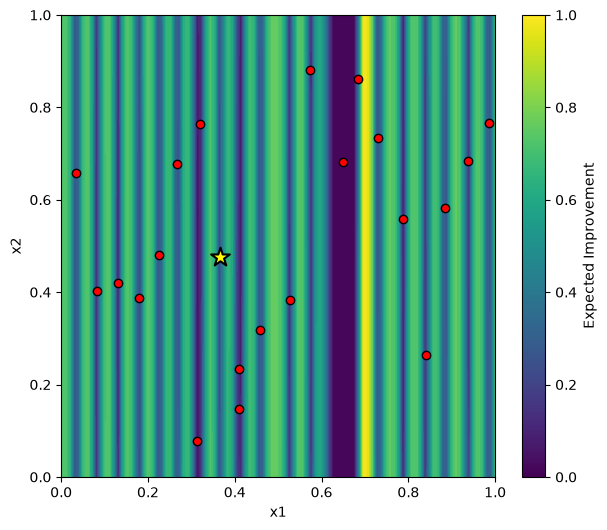

In [61]:
def plot_EI_slice(gp, X, Y, dim1=0, dim2=1, resolution=100, xi=0):
    """
    Plot a 2D slice of the Expected Improvement acquisition function.

    Parameters
    ----------
    gp : fitted GaussianProcessRegressor
    X : observed inputs (n_samples, n_features)
    Y : observed outputs
    dim1 : first variable to plot
    dim2 : second variable to plot
    """

    best_point = X[np.argmax(Y)].copy()

    x = np.linspace(0, 1, resolution)
    y = np.linspace(0, 1, resolution)

    xx, yy = np.meshgrid(x, y)

    grid = np.tile(best_point, (xx.size, 1))

    grid[:, dim1] = xx.ravel()
    grid[:, dim2] = yy.ravel()

    mu, sigma = gp.predict(grid, return_std=True)

    best_y = np.max(Y)

    improvement = mu - best_y - xi

    EI = np.zeros_like(mu)

    mask = sigma > 0

    Z = np.zeros_like(mu)
    Z[mask] = improvement[mask] / sigma[mask]

    EI[mask] = (
        improvement[mask] * norm.cdf(Z[mask])
        + sigma[mask] * norm.pdf(Z[mask])
    )

    plt.figure(figsize=(7,6))

    plt.contourf(xx, yy, EI.reshape(xx.shape), levels=30, cmap="viridis")

    plt.scatter(
        X[:, dim1],
        X[:, dim2],
        c="red",
        edgecolor="black"
    )

    plt.scatter(
    best_point[dim1],
    best_point[dim2],
    c="yellow",
    edgecolor="black",
    s=200,
    marker="*",
    linewidth=1.5,
    label="Current best"
    )

    plt.xlabel(f"x{dim1+1}")
    plt.ylabel(f"x{dim2+1}")

    plt.colorbar(label="Expected Improvement")

    plt.show()

plot_EI_slice(gp, X, Y, dim1=0, dim2=1)

In [ ]:
'''
1st point selected: [0.937078-0.684657]
Output: -5.598797971755511e-69 

2nd point selected: [0.788288-0.558666]
Output: -1.401399910656819e-21

3rd point selected: [0.527018-0.382925]
Output: -2.3250629511906966e-11

4th point selected: [0.459283-0.317126]
Output: -8.21331379257691e-11

5th point selected: [0.034792-0.658504]
Output: 1.1222909718961177e-143

6th point selected: [0.984957-0.765092]
Output: -9.598914422468103e-103

7th point selected: [0.130397-0.420704]
Output: 8.158420809101271e-60

8th point selected: [0.178341-0.387543]
Output: -2.7314916093586457e-43

9th point selected: [0.226359-0.481246]
Output: -4.254685262921865e-31 

10th point selected: [0.366681-0.475455]
Output: 2.5011329098923868e-05   ---NEW BEST---

11th point selected: [0.410839-0.234113]
Output: 1.093724485480335e-25 

12th point selected: [0.267811-0.678355]  --- xi reduced from 0.01 to 0.005 ---
Output: -3.5675899263299964e-63 

Final point selected: [0.410839-0.475455]   --- xi reduced to 0, MANUALLY SELECTED by combining points 10 and 11 ---
Output: -0.003981331842453507

In [ ]:
# Updating data with new input-output pairs

# X_query1 = np.array([0.937078, 0.684657], dtype=np.float64)
# Y_query1_output = np.array([-5.598797971755511e-69], dtype=np.float64)
# X_updated = np.vstack((X, X_query1))
# Y_updated = np.append(Y, Y_query1_output)

# X_query2 = np.array([0.788288,0.558666], dtype=np.float64)
# Y_query2_output = np.array([-1.401399910656819e-21], dtype=np.float64)
# X_updated = np.vstack((X, X_query2))
# Y_updated = np.append(Y, Y_query2_output)

# X_query3 = np.array([0.527018,0.382925], dtype=np.float64)
# Y_query3_output = np.array([-2.3250629511906966e-11], dtype=np.float64)
# X_updated = np.vstack((X, X_query3))
# Y_updated = np.append(Y, Y_query3_output)

# X_query4 = np.array([0.459283,0.317126], dtype=np.float64)
# Y_query4_output = np.array([-8.21331379257691e-11], dtype=np.float64)
# X_updated = np.vstack((X, X_query4))
# Y_updated = np.append(Y, Y_query4_output)

# X_query5 = np.array([0.034792,0.658504], dtype=np.float64)
# Y_query5_output = np.array([1.1222909718961177e-143], dtype=np.float64)
# X_updated = np.vstack((X, X_query5))
# Y_updated = np.append(Y, Y_query5_output)

# X_query6 = np.array([0.984957,0.765092], dtype=np.float64)
# Y_query6_output = np.array([-9.598914422468103e-103], dtype=np.float64)
# X_updated = np.vstack((X, X_query6))
# Y_updated = np.append(Y, Y_query6_output)

# X_query7 = np.array([0.130397,0.420704], dtype=np.float64)
# Y_query7_output = np.array([8.158420809101271e-60], dtype=np.float64)
# X_updated = np.vstack((X, X_query7))
# Y_updated = np.append(Y, Y_query7_output)

# X_query8 = np.array([0.178341,0.387543], dtype=np.float64)
# Y_query8_output = np.array([-2.7314916093586457e-43], dtype=np.float64)
# X_updated = np.vstack((X, X_query8))
# Y_updated = np.append(Y, Y_query8_output)

# X_query9 = np.array([0.226359,0.481246], dtype=np.float64)
# Y_query9_output = np.array([-4.254685262921865e-31], dtype=np.float64)
# X_updated = np.vstack((X, X_query9))
# Y_updated = np.append(Y, Y_query9_output)

# X_query10 = np.array([0.366681,0.475455], dtype=np.float64)
# Y_query10_output = np.array([2.5011329098923868e-05], dtype=np.float64)
# X_updated = np.vstack((X, X_query10))
# Y_updated = np.append(Y, Y_query10_output)

# X_query11 = np.array([0.410839,0.234113], dtype=np.float64)
# Y_query11_output = np.array([1.093724485480335e-25], dtype=np.float64)
# X_updated = np.vstack((X, X_query11))
# Y_updated = np.append(Y, Y_query11_output)

# X_query12 = np.array([0.267811,0.678355], dtype=np.float64)
# Y_query12_output = np.array([-3.5675899263299964e-63], dtype=np.float64)
# X_updated = np.vstack((X, X_query12))
# Y_updated = np.append(Y, Y_query12_output)

# X_query13 = np.array([0.410839,0.475455], dtype=np.float64)
# Y_query13_output = np.array([-0.003981331842453507], dtype=np.float64)
# X_updated = np.vstack((X, X_query13))
# Y_updated = np.append(Y, Y_query13_output)

In [ ]:
# Save new data to original files (initial_inputs.npy & initial_outputs.npy)

# np.save(r"initial_data\function_1\initial_inputs.npy", X_updated)
# np.save(r"initial_data\function_1\initial_outputs.npy", Y_updated)